# Gradient boosting: XGBoost (issue #11)

Follows the shared evaluation protocol (`src/common.py`, issue #8): development data = train + val, repeated stratified 5-fold CV x 3, seed 42, test set untouched.

Tuned scores use **nested CV** (the hyper-parameter search runs only inside each outer training fold), so they are not inflated by tuning. Same method as `boosting_sklearn.ipynb` (#10) and `boosting_lightgbm.ipynb` (#12).

Early stopping: the shared `evaluate()` has no validation hook, so early stopping is shown on the official train/val split (section 3) and used to sanity-check the tuned `n_estimators`; it is never run on the test set.

Needs XGBoost: `pip install xgboost`.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate

from src.common import (load_dev, load_train_val, evaluate, get_cv, log_result, _who,
                        SCORING, RANDOM_STATE, ROOT)
warnings.filterwarnings('ignore')

X, y = load_dev()
# n_jobs=1 inside each model: folds already run in parallel, and this keeps fit times comparable
BASE = dict(random_state=RANDOM_STATE, n_jobs=1, tree_method='hist', eval_metric='auc')
print(X.shape)

(16604, 6)


## 1. Default settings (logged)

In [2]:
default = evaluate(XGBClassifier(**BASE), X, y, name='XGBoost', params={'defaults': True}, n_jobs=-1,
                   notes='fit time measured with n_jobs=1 per model')
cols = ['model', 'cv_auc_mean', 'cv_auc_std', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean', 'fit_time_mean_s']
pd.DataFrame([default])[cols]

,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,XGBoost,0.662,0.0109,0.7699,0.737,0.79,0.6907,0.084


## 2. Tuning with nested CV

`RandomizedSearchCV`, 25 settings, inner 3-fold CV on each outer training part, scored by ROC AUC. Searched: `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`, `min_child_weight`, `reg_alpha`, `reg_lambda`.

In [3]:
SPACE = {'n_estimators': randint(100, 501), 'learning_rate': loguniform(0.01, 0.2),
         'max_depth': randint(2, 7), 'subsample': uniform(0.6, 0.4),
         'colsample_bytree': uniform(0.6, 0.4), 'min_child_weight': randint(1, 31),
         'reg_alpha': loguniform(1e-3, 10), 'reg_lambda': loguniform(1e-3, 10)}
N_ITER, INNER_CV = 25, StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def make_search(seed=RANDOM_STATE):
    return RandomizedSearchCV(XGBClassifier(**BASE), SPACE, n_iter=N_ITER, cv=INNER_CV, scoring='roc_auc',
                              random_state=seed, n_jobs=1, refit=True)

t = time.time()
res = cross_validate(make_search(), X, y, cv=get_cv(), scoring=SCORING, n_jobs=-1)
tuned = {'date': date.today().isoformat(), 'who': _who(), 'model': 'XGBoost tuned', 'features': 'raw',
         'params': f'RandomizedSearchCV n_iter={N_ITER}', 'n_rows': len(X),
         'fit_time_mean_s': round(float(np.mean(res['fit_time'])), 1),
         'notes': 'NESTED CV (search inside each outer training fold); fit time includes the search'}
for k in SCORING:
    tuned[f'cv_{k}_mean'] = round(float(np.mean(res[f'test_{k}'])), 4)
    tuned[f'cv_{k}_std'] = round(float(np.std(res[f'test_{k}'])), 4)
log_result(tuned)

best_search = make_search().fit(X, y)
best_params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in best_search.best_params_.items()}
(ROOT / 'results' / 'best_params_xgboost.json').write_text(json.dumps(best_params, indent=2))
print(f'nested AUC {tuned["cv_auc_mean"]} +/- {tuned["cv_auc_std"]} ({time.time()-t:.0f}s)')
print('final params:', best_params)

nested AUC 0.7018 +/- 0.0088 (18s)
final params: {'colsample_bytree': 0.6147547789418131, 'learning_rate': 0.062095693648805635, 'max_depth': 3, 'min_child_weight': 28, 'n_estimators': 153, 'reg_alpha': 0.0013558227959926895, 'reg_lambda': 0.024004075943521632, 'subsample': 0.8537405378805455}


## 3. Early stopping and overfitting check

Train on the official `train` split, early-stop on `val` (never on test). Shows how many rounds the validation AUC wants versus the tuned `n_estimators`.

early-stopped at round 11 | val AUC 0.7013 | tuned n_estimators 153


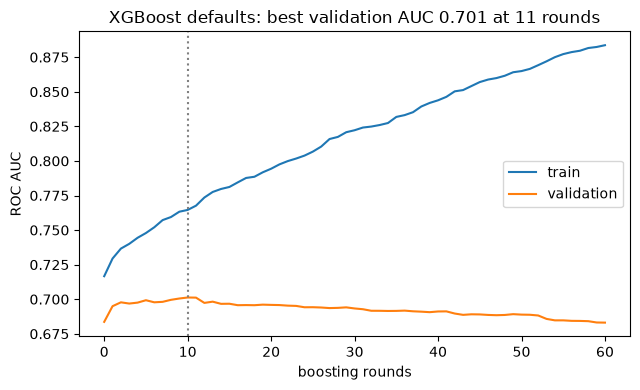

In [4]:
X_tr, y_tr, X_va, y_va = load_train_val()
m = XGBClassifier(n_estimators=600, early_stopping_rounds=50, **BASE).fit(
    X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)], verbose=False)
ev = m.evals_result()
tr, va = ev['validation_0']['auc'], ev['validation_1']['auc']
print('early-stopped at round', m.best_iteration + 1, '| val AUC', round(m.best_score, 4),
      '| tuned n_estimators', best_params['n_estimators'])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tr, label='train'); ax.plot(va, label='validation')
ax.axvline(m.best_iteration, ls=':', c='gray')
ax.set_title(f'XGBoost defaults: best validation AUC {m.best_score:.3f} at {m.best_iteration+1} rounds')
ax.set_xlabel('boosting rounds'); ax.set_ylabel('ROC AUC'); ax.legend()
(ROOT / 'reports' / 'figures').mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / 'boosting_xgboost_overfit.png', dpi=130); plt.show()

## 4. Feature importance (gain) of the tuned model

Indicative only; permutation importance and SHAP are in #16.

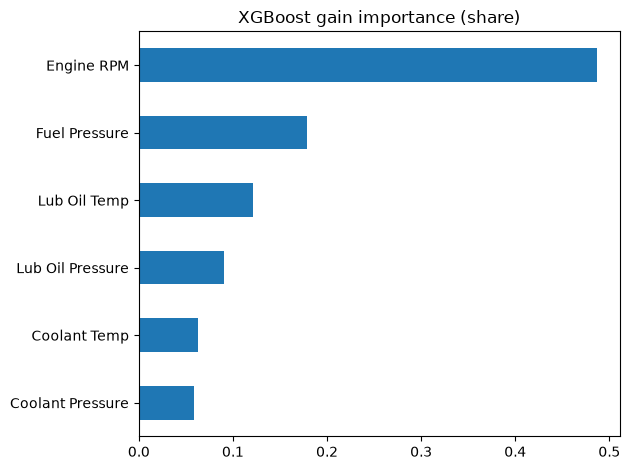

In [5]:
final = XGBClassifier(importance_type='gain', **BASE, **best_params).fit(X, y)
imp = pd.Series(final.feature_importances_, index=X.columns).sort_values()
(imp / imp.sum()).plot.barh(title='XGBoost gain importance (share)'); plt.tight_layout(); plt.show()